# 2. Creating Time-Dependent Input Curves

So far, every rate constant in our models has been a **fixed number** (like `k1_Aexp = 1`) that stays frozen from start to finish.

Real cells don't live in a frozen world! A healthy immune cell sits quietly at rest, then suddenly detects a pathogen or cytokine for a short burst, and later the signal fades away. To mimic real biology — including **NEMO/IKK** and **NIK** signalling in our published NF-κB model — we need **time-dependent input curves**: inputs whose strength changes automatically as simulation time `t` moves forward.

Don't worry if you don't have a maths or computer science background — we'll build every single concept from scratch using pictures and everyday analogies!

---

## Maths Made Simple: What Is a "Function of Time" $f(t)$?

Think of a **function of time** $f(t)$ as a **dimmer switch on a timer**:
- You hand it **any time `t`** (say, `t = 12.5` minutes).
- It hands back **one number**: how strong the biological signal is at that exact minute!

In Julia, there are two completely equivalent ways to write a function of time:

1. **Compact arrow syntax** (great for short one-line rules):
   ```julia
   basalInput = t -> 0.5
   ```
   Read `t -> 0.5` out loud as: *"given any time `t`, return `0.5`."*

2. **Named multi-line `function`** (great when your curve has `if`/`else` steps or multiple lines):
   ```julia
   function pulseInput(t)
       if t >= 10 && t <= 30
           return 5.0
       else
           return 0.5
       end
   end
   ```

:::{note} What does the dot `.` mean in `pulseInput.(times)`?
In Julia, putting a dot right before `(` — like `pulseInput.(times)` — simply means: **"run `pulseInput(t)` for every single time point in the list `times`!"** That makes plotting any input curve a one-liner.
:::

---

## Four Essential Biological Input Shapes

Nearly every time-dependent input used in systems biology is built from one of **four simple shapes**:

1. **Constant (resting / steady-state) input:** A flat horizontal line (`t -> 0.5`). Used when a cell sits at rest or under chronic, unchanging stimulation.
2. **Square pulse (on/off step):** Jumps up when a stimulus is added and drops back down when it is washed away (`if t >= 10 && t <= 30 ...`).
3. **Smooth decay curve:** Starts high and gradually fades away, like a signal wearing off over time:
   $$f(t) = \frac{1}{1 + t / 60}$$
   Let's check this formula with three easy numbers (no algebra required!):
   - At $t = 0\text{ min}$: $\frac{1}{1 + 0} = \mathbf{1.0}$ (100% strength)
   - At $t = 60\text{ min}$: $\frac{1}{1 + 1} = \mathbf{0.5}$ (dropped to half!)
   - At $t = 180\text{ min}$: $\frac{1}{1 + 3} = \mathbf{0.25}$ (dropped to a quarter!)
   *(We actually use this exact formula in our lab's NF-κB code to smoothly turn down NIK degradation!)*
4. **Piecewise linear interpolation from experimental measurements ("connecting the dots"):**
   What if a collaborator hands you wet-lab measurements of active IKK taken at specific minutes — say `0, 5, 10, 15, 18, 20, 300, ...` — and you want to feed that real experimental curve into Julia?

```{figure} ../images/linear-interpolation.svg
:alt: Intuitive explanation of linear interpolation between measured timepoints using rise over run
:width: 100%

**Linear interpolation in plain English:** The ODE solver needs to know the input value at *any* time `t` (like `t = 2.5 min`), even between your measured lab timepoints. Linear interpolation simply connects each pair of neighbouring dots with a straight line and reads off the height at `t`!
```

Let's build and plot **all four shapes** live in Julia right now — including the **exact `ikkDefault` linear-interpolation function** from [`SiFTW/NFkBModel`](https://github.com/SiFTW/NFkBModel)!

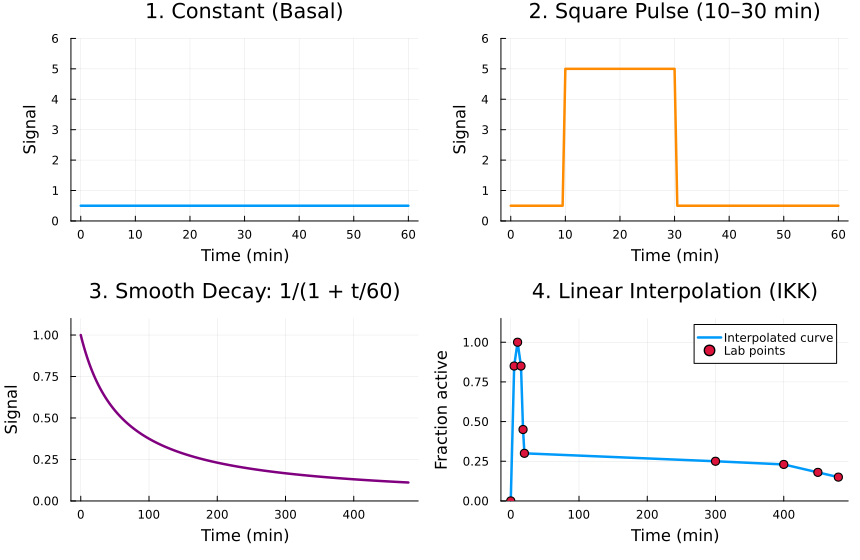

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Shape 1: Constant basal input
constantInput = t -> 0.5

# Shape 2: Square pulse (ON between 10 and 30 min)
function pulseInput(t)
    if t >= 10.0 && t <= 30.0
        return 5.0
    else
        return 0.5
    end
end

# Shape 3: Smooth decay (halves after 60 min)
smoothDecay = t -> 1.0 / (1.0 + t / 60.0)

# Shape 4: Experimental data points connected by linear interpolation!
# (This is the exact canonical IKK activity curve from SiFTW/NFkBModel!)
const IKK_TIMES = [0.0, 5.0, 10.0, 15.0, 18.0, 20.0, 300.0, 400.0, 450.0, 480.0, 500.0, 520.0, 2880.0]
const IKK_VALS  = [0.0, 85.0, 100.0, 85.0, 45.0, 30.0, 25.0, 23.0, 18.0, 15.0, 12.0, 10.0, 10.0] ./ 100.0

function ikkDefault(t, maxTime=480.0)
    paramTime = copy(IKK_TIMES)
    paramTime[end] = max(maxTime, 2880.0)

    # Step 1: Find the measured dot just after t, and the dot just before t
    indexAfter  = min(searchsortedfirst(paramTime, t), length(paramTime))
    indexBefore = max(1, indexAfter - 1)

    tAfter,  tBefore  = paramTime[indexAfter], paramTime[indexBefore]
    vAfter,  vBefore  = IKK_VALS[indexAfter],  IKK_VALS[indexBefore]
    timeGap = tAfter - tBefore

    # Step 2 & 3: If t is strictly between two dots, walk along the straight line!
    if timeGap > 0
        slope = (vAfter - vBefore) / timeGap   # rise divided by run
        return vBefore + slope * (t - tBefore)
    else
        return vBefore
    end
end

# Plot all four biological input shapes in a 2x2 grid
t_short = 0.0:0.5:60.0
t_long  = 0.0:1.0:480.0

p1 = plot(t_short, constantInput.(t_short), lw=2.5, ylim=(0, 6), label=false,
          title="1. Constant (Basal)", xlabel="Time (min)", ylabel="Signal")
p2 = plot(t_short, pulseInput.(t_short), lw=2.5, ylim=(0, 6), label=false, color=:darkorange,
          title="2. Square Pulse (10–30 min)", xlabel="Time (min)", ylabel="Signal")
p3 = plot(t_long, smoothDecay.(t_long), lw=2.5, ylim=(0, 1.1), label=false, color=:purple,
          title="3. Smooth Decay: 1/(1 + t/60)", xlabel="Time (min)", ylabel="Signal")
p4 = plot(t_long, [ikkDefault(t, 480.0) for t in t_long], lw=2.5, ylim=(0, 1.15), label="Interpolated curve",
          title="4. Linear Interpolation (IKK)", xlabel="Time (min)", ylabel="Fraction active")
# Overlay the actual experimental data points up to 480 min!
measured_mask = IKK_TIMES .<= 480.0
scatter!(p4, IKK_TIMES[measured_mask], IKK_VALS[measured_mask], ms=4.5, color=:crimson, label="Lab points")

plot(p1, p2, p3, p4, layout=(2, 2), size=(860, 560))

### Quick Check: Test Your Understanding of Input Curves

1. Look at `IKK_TIMES` and `IKK_VALS` above: at `t = 0` min the measured value is `0.00`, and at `t = 5` min it is `0.85`. What value does `ikkDefault(2.5)` return?
   ````{admonition} Hint
   :class: dropdown tip
   `t = 2.5` is **exactly halfway** between `t = 0` and `t = 5`!
   ````
   ````{admonition} Reveal Answer
   :class: dropdown note
   **`0.425`** (exactly halfway between `0.00` and `0.85`)! Using the formula: $\text{slope} = \frac{0.85 - 0}{5 - 0} = 0.17\text{ per min}$, so $0 + 0.17 \times 2.5 = 0.425$.
   ````

2. What does `smoothDecay(t) = 1.0 / (1.0 + t / 60.0)` equal at `t = 120` minutes?
   ````{admonition} Hint
   :class: dropdown tip
   First calculate `120 / 60 = 2`, then plug into `1 / (1 + 2)`.
   ````
   ````{admonition} Reveal Answer
   :class: dropdown note
   **$\frac{1}{3} \approx 0.333$**!
   ````

---

## Wiring Time-Dependent Curves into `CSV2Julia` (The `(t)` Rule!)

Now comes the magic that connects everything in Chapter 1 to real published models!

How does `CSV2Julia` know that one of your parameters is a **time-dependent function** rather than a plain fixed number?

**It simply checks whether `(t)` appears in the `Value` column of `parameters.csv`!**

Look at our Toy Model's `parameters.csv` if we make protein **A**'s expression rate (`k1_Aexp`) time-dependent:

```text
Parameter , Value
k1_Aexp   , t->inputFunc(t)
k1_AtoB   , 2
k1_BtoC   , 3
k1_Cdeg   , 4
```

When you run `csv2model-multiscale.py` in **`param` mode**:
1. In the generated ODE file, **`CSV2Julia` writes `p[1](t)`** (with `(t)` at the end!) instead of `p[1]`, so at every single instant `t` during the simulation, Julia calls the function stored in `p[1]`!
2. In `scanIncludes.jl`, **`paramVals[1]` stores `t->inputFunc(t)`** — and because it's just a slot in the `paramVals` vector, **you can swap `myParams[1]` for ANY input curve you want at run-time** (`constantInput`, `pulseInput`, `ikkDefault`, etc.) without ever regenerating the ODE file!

:::{tip} Why doesn't `include("scanIncludes.jl")` complain if `inputFunc` isn't defined yet?
In Julia, `t -> inputFunc(t)` only creates a placeholder function — it doesn't actually look up `inputFunc` until someone *calls* it! So as long as you either define `inputFunc(t)` OR overwrite `myParams[idx] = myCustomCurve` before calling `solve(...)`, everything works smoothly!
:::

Let's see this live on the **Toy Model** right now!

In [2]:
# Create a time-dependent version of parameters.csv for the Toy Model
write("parameters_td.csv", """
Parameter , Value
k1_Aexp   , t->inputFunc(t)
k1_AtoB   , 0.2
k1_BtoC   , 0.2
k1_Cdeg   , 0.2
""")

# Build in PARAM mode!
run(`python3 csv2model-multiscale.py reactions.csv parameters_td.csv ratelaws.csv toy_td.jl param`)

println("--- Notice p[1](t) in the generated toy_td.jl! ---")
println(read("toy_td.jl", String))

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening ratelaws.csv as rate law file
Opening parameters_td.csv as parameters file
Opening reactions.csv as reactions file
--- Notice p[1](t) in the generated toy_td.jl! ---
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions.csv
#    parameters file file: parameters_td.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:3
#    Parameters:4
#######################################################



function toy_td(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[3],0])
	#A
	dy[1]= + p[1](t) - A * p[2]
	#B
	dy[2]= + A * p[2] - B * p[3]
	#C
	dy[3]= + B * p[3] - C * p[4]
end



Look at `dy[1]= + p[1](t) - A * p[2]` — **`CSV2Julia` automatically added `(t)` to `p[1]`** because `parameters_td.csv` contained `(t)`!

Now watch how we can swap **two completely different input curves** (`constantInput` vs `pulseInput`) into `myParams[idx_Aexp]` at run-time and see how the $A \to B \to C$ cascade responds!

parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


┌ Warning: Using arrays or dicts to store parameters of different types can hurt performance.
│ Consider using tuples instead.
└ @ SciMLBase /tmp/julia-depot/packages/SciMLBase/Zzjmy/src/performance_warnings.jl:33


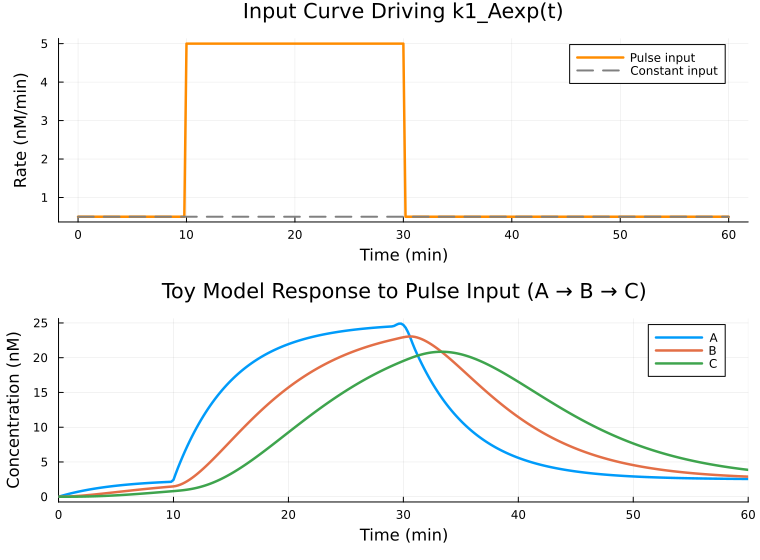

In [3]:
include("toy_td.jl")
include("variableNames.jl")
include("scanIncludes.jl")

idx_Aexp = findfirst(x -> x == "k1_Aexp", parameterNameList)
y0 = [0.0, 0.0, 0.0]
tspan = (0.0, 60.0)

# Condition 1: Constant low input
p_const = copy(paramVals)
p_const[idx_Aexp] = constantInput
sol_const = solve(ODEProblem(ODEFunction(toy_td), y0, tspan, p_const), saveat=0.2)

# Condition 2: Square pulse of synthesis between t = 10 and t = 30 min!
p_pulse = copy(paramVals)
p_pulse[idx_Aexp] = pulseInput
sol_pulse = solve(ODEProblem(ODEFunction(toy_td), y0, tspan, p_pulse), saveat=0.2)

plt_in = plot(sol_pulse.t, pulseInput.(sol_pulse.t), lw=2.5, color=:darkorange, label="Pulse input",
              title="Input Curve Driving k1_Aexp(t)", xlabel="Time (min)", ylabel="Rate (nM/min)")
plot!(plt_in, sol_const.t, constantInput.(sol_const.t), lw=2.0, ls=:dash, color=:gray, label="Constant input")

plt_out = plot(sol_pulse, label=permutedims(syms), lw=2.5,
               title="Toy Model Response to Pulse Input (A → B → C)",
               xlabel="Time (min)", ylabel="Concentration (nM)")

plot(plt_in, plt_out, layout=(2, 1), size=(760, 560))

Look at that biological wave propagating down the cascade:
- When the pulse switches **ON** at `t = 10 min`, **A** shoots up immediately, followed by **B** (delayed!), and then **C** (delayed even further!).
- When the pulse switches **OFF** at `t = 30 min`, **A** drops first, while **B** and **C** keep peaking briefly before falling back to resting levels!

---

## Hands-on Exercise: Design Your Own Dynamic Input Curves!

### Challenge 1: Build a **Double-Pulse** Stimulus on the Toy Model

In real immunity, cells often experience repeated waves of stimulation.

**Your task:** Edit `doublePulse(t)` below so that:
- `k1_Aexp(t)` is **`5.0`** during **Pulse 1** (`5 ≤ t ≤ 15` min)
- `k1_Aexp(t)` is **`5.0`** again during **Pulse 2** (`35 ≤ t ≤ 45` min)
- Otherwise it stays at a resting basal level of **`0.2`**.

Swap `doublePulse` into `paramVals` at run-time and watch whether `A`, `B`, and `C` show two distinct waves!

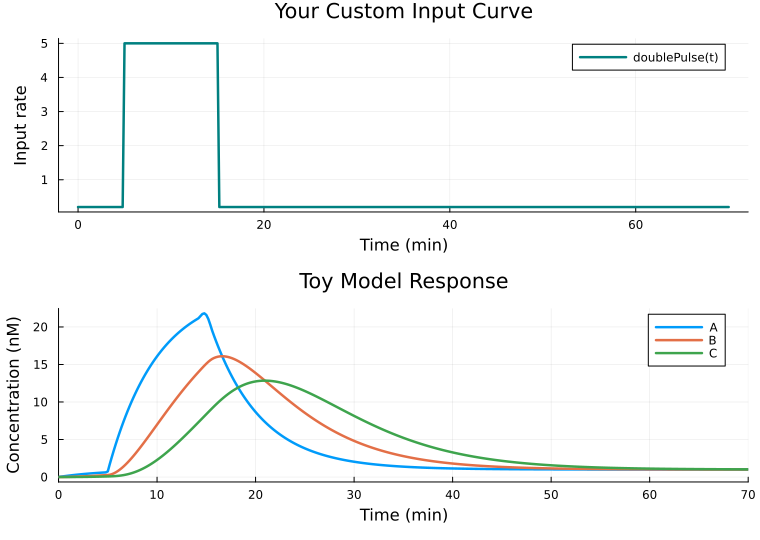

In [4]:
# Challenge 1: Edit doublePulse(t) to fire TWO pulses (5–15 min and 35–45 min)!
function doublePulse(t)
    if t >= 5.0 && t <= 15.0
        return 5.0
    else
        return 0.2
    end
end

p_dp = copy(paramVals)
p_dp[idx_Aexp] = doublePulse
sol_dp = solve(ODEProblem(ODEFunction(toy_td), [0.0, 0.0, 0.0], (0.0, 70.0), p_dp), saveat=0.2)

p_top = plot(sol_dp.t, doublePulse.(sol_dp.t), lw=2.5, color=:teal, label="doublePulse(t)",
             title="Your Custom Input Curve", xlabel="Time (min)", ylabel="Input rate")
p_bot = plot(sol_dp, label=permutedims(syms), lw=2.5,
             title="Toy Model Response", xlabel="Time (min)", ylabel="Concentration (nM)")
plot(p_top, p_bot, layout=(2, 1), size=(760, 540))

```{admonition} Hint
:class: dropdown tip

Add an `elseif` branch to `doublePulse(t)` for the second pulse:
`elseif t >= 35.0 && t <= 45.0` → `return 5.0`!
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
function doublePulse(t)
    if t >= 5.0 && t <= 15.0
        return 5.0
    elseif t >= 35.0 && t <= 45.0
        return 5.0
    else
        return 0.2
    end
end

p_dp = copy(paramVals)
p_dp[idx_Aexp] = doublePulse
sol_dp = solve(ODEProblem(ODEFunction(toy_td), [0.0, 0.0, 0.0], (0.0, 70.0), p_dp), saveat=0.2)

p_top = plot(sol_dp.t, doublePulse.(sol_dp.t), lw=2.5, color=:teal, label="doublePulse(t)",
             title="Double-Pulse Input Curve", xlabel="Time (min)", ylabel="Input rate")
p_bot = plot(sol_dp, label=permutedims(syms), lw=2.5,
             title="Toy Model Response to Two Pulses", xlabel="Time (min)", ylabel="Concentration (nM)")
plot(p_top, p_bot, layout=(2, 1), size=(760, 540))
```
````

### Challenge 2: Drive the Toy Model with Linearly Interpolated Experimental Points!

Suppose you measured an input signal in the lab at five timepoints:

| Time (min) | 0 | 5 | 15 | 30 | 60 |
|---|---|---|---|---|---|
| Signal | 0.2 | 4.0 | 2.0 | 0.8 | 0.2 |

**Your task:** Fill in `myTimes` and `myVals` below (using our linear interpolation helper) and drive `toy_td` with `myExpCurve`! Try changing the peak at `t = 5` min from `4.0` to `8.0` or stretching the decay tail at `t = 30` min to see how downstream species `C` responds!

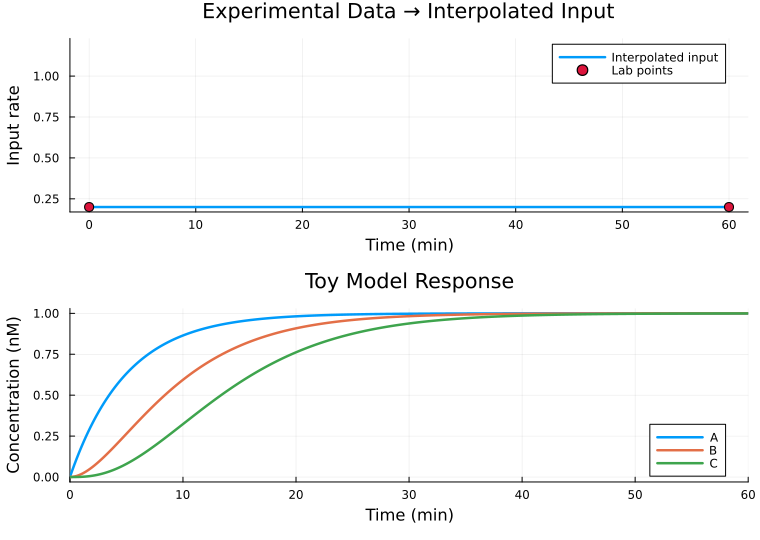

In [5]:
# Challenge 2: Edit myTimes and myVals to build your own linearly interpolated input!
function makeLinearCurve(times, vals)
    return function (t)
        idx_after  = min(searchsortedfirst(times, t), length(times))
        idx_before = max(1, idx_after - 1)
        dt = times[idx_after] - times[idx_before]
        if dt > 0
            slope = (vals[idx_after] - vals[idx_before]) / dt
            return vals[idx_before] + slope * (t - times[idx_before])
        else
            return vals[idx_before]
        end
    end
end

# Currently flat — replace with the 5 lab measurements from the table above!
myTimes = [0.0, 60.0]
myVals  = [0.2, 0.2]

myExpCurve = makeLinearCurve(myTimes, myVals)

p_exp = copy(paramVals)
p_exp[idx_Aexp] = myExpCurve
sol_exp = solve(ODEProblem(ODEFunction(toy_td), [0.0, 0.0, 0.0], (0.0, 60.0), p_exp), saveat=0.2)

p_top = plot(sol_exp.t, myExpCurve.(sol_exp.t), lw=2.5, label="Interpolated input",
             title="Experimental Data → Interpolated Input", xlabel="Time (min)", ylabel="Input rate")
scatter!(p_top, myTimes, myVals, ms=5, color=:crimson, label="Lab points")

p_bot = plot(sol_exp, label=permutedims(syms), lw=2.5,
             title="Toy Model Response", xlabel="Time (min)", ylabel="Concentration (nM)")
plot(p_top, p_bot, layout=(2, 1), size=(760, 540))

```{admonition} Hint
:class: dropdown tip

Set:
```julia
myTimes = [0.0, 5.0, 15.0, 30.0, 60.0]
myVals  = [0.2, 4.0, 2.0,  0.8,  0.2]
```
Notice how `makeLinearCurve(times, vals)` returns a reusable function of time `t` that you can plug straight into `p_exp[idx_Aexp]`!
```

````{admonition} Reveal Solution
:class: dropdown note

```julia
myTimes = [0.0, 5.0, 15.0, 30.0, 60.0]
myVals  = [0.2, 4.0, 2.0,  0.8,  0.2]

myExpCurve = makeLinearCurve(myTimes, myVals)

p_exp = copy(paramVals)
p_exp[idx_Aexp] = myExpCurve
sol_exp = solve(ODEProblem(ODEFunction(toy_td), [0.0, 0.0, 0.0], (0.0, 60.0), p_exp), saveat=0.2)

p_top = plot(sol_exp.t, myExpCurve.(sol_exp.t), lw=2.5, label="Interpolated input",
             title="Experimental Data → Interpolated Input", xlabel="Time (min)", ylabel="Input rate")
scatter!(p_top, myTimes, myVals, ms=5, color=:crimson, label="Lab points")

p_bot = plot(sol_exp, label=permutedims(syms), lw=2.5,
             title="Toy Model Response", xlabel="Time (min)", ylabel="Concentration (nM)")
plot(p_top, p_bot, layout=(2, 1), size=(760, 540))
```
````

You now have **every single building block** needed to run a real, published Mitchell Lab signalling model!

Head to **[3. Running the Published NF-κB Model](./03-published-nfkb-model.ipynb)** to put `CSV2Julia`, `param` mode, runtime parameter edits, and time-dependent NEMO/IKK & NIK input curves to work on the full **101-species NF-κB model**!